# Neural Network 4L
A 4-layer neural network: input layer -> hidden layer 1 -> hidden layer 2 -> output layer (PyTorch).

In [1]:
import os
import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

# small networks train faster on a single cpu thread
torch.set_num_threads(1)

# folders for saved figures and tables (used in the report)
FIG_DIR = "figures/4L"
RESULTS_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.10.0


## Data Loading and Preprocessing

In [2]:
# load the same three datasets used for the 2L network
airfoil = pd.read_csv("../data/airfoil.csv")
auto = pd.read_csv("../data/auto_mpg.csv")
concrete = pd.read_csv("../data/concrete.csv")

# dataset name -> (dataframe, target column)
datasets = {
    "Airfoil": (airfoil, "scaled_sound_pressure_db"),
    "Auto MPG": (auto, "mpg"),
    "Concrete": (concrete, "compressive_strength_mpa")
}

for name, (df, target) in datasets.items():
    missing = df.isnull().sum().sum()
    print(f"{name}: shape={df.shape}, target={target}, missing values={missing}")

Airfoil: shape=(1503, 6), target=scaled_sound_pressure_db, missing values=0
Auto MPG: shape=(392, 8), target=mpg, missing values=0
Concrete: shape=(1030, 9), target=compressive_strength_mpa, missing values=0


In [3]:
# separate predictors and target, then split into 80% training and 20% validation
# (same random_state as the 2L notebook so both models see identical splits)
splits = {}

for name, (df, target) in datasets.items():
    X = df.drop(columns=[target])
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )
    splits[name] = (X_train, X_test, y_train, y_test)
    print(f"{name}: train={X_train.shape}, validation={X_test.shape}")

Airfoil: train=(1202, 5), validation=(301, 5)
Auto MPG: train=(313, 7), validation=(79, 7)
Concrete: train=(824, 8), validation=(206, 8)


## Neural Network Setup

In [4]:
# standardize predictors and target using training data only, then convert to tensors
# the target is standardized because the hidden layers train poorly on raw targets
# such as airfoil (~125 dB); predictions are converted back to the original scale for QoF
def prepare_data(X_train, X_test, y_train, y_test):
    x_scaler = StandardScaler()
    X_train = x_scaler.fit_transform(X_train)
    X_test = x_scaler.transform(X_test)

    y_scaler = StandardScaler()
    y_train_s = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1))
    y_test_s = y_scaler.transform(y_test.to_numpy().reshape(-1, 1))

    tensors = {
        "X_train": torch.tensor(X_train, dtype=torch.float32),
        "X_test": torch.tensor(X_test, dtype=torch.float32),
        "y_train_s": torch.tensor(y_train_s, dtype=torch.float32),  # scaled targets for training
        "y_test_s": torch.tensor(y_test_s, dtype=torch.float32),
        "y_train": y_train.to_numpy().reshape(-1, 1),               # original-scale targets for QoF
        "y_test": y_test.to_numpy().reshape(-1, 1)
    }
    return tensors, y_scaler

data = {}
for name, (X_train, X_test, y_train, y_test) in splits.items():
    data[name] = prepare_data(X_train, X_test, y_train, y_test)
    t = data[name][0]
    print(f"{name} Tensors: X_train={tuple(t['X_train'].shape)}, y_train={tuple(t['y_train_s'].shape)}")

Airfoil Tensors: X_train=(1202, 5), y_train=(1202, 1)
Auto MPG Tensors: X_train=(313, 7), y_train=(313, 1)
Concrete Tensors: X_train=(824, 8), y_train=(824, 1)


In [5]:
# define 4-layer neural network: input -> hidden 1 -> hidden 2 -> output
class NeuralNet4L(nn.Module):
    def __init__(self, input_size, hidden1, hidden2, activation):
        super().__init__()
        self.hidden1 = nn.Linear(input_size, hidden1)  # input -> hidden layer 1
        self.act1 = activation()                       # hidden layer 1 activation function
        self.hidden2 = nn.Linear(hidden1, hidden2)     # hidden layer 1 -> hidden layer 2
        self.act2 = activation()                       # hidden layer 2 activation function
        self.output = nn.Linear(hidden2, 1)            # hidden layer 2 -> output layer (identity for regression)

    def forward(self, x):
        x = self.act1(self.hidden1(x))
        x = self.act2(self.hidden2(x))
        return self.output(x)

# example architecture
print(NeuralNet4L(5, 32, 16, nn.ReLU))

NeuralNet4L(
  (hidden1): Linear(in_features=5, out_features=32, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=32, out_features=16, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=16, out_features=1, bias=True)
)


## Hyperparameter Tuning

In [6]:
# hyperparameter search space
hidden_sizes = [(16, 8), (32, 16), (64, 32), (128, 64)]   # nodes in (hidden 1, hidden 2)
activations = {"ReLU": nn.ReLU, "Tanh": nn.Tanh, "Sigmoid": nn.Sigmoid}
batch_sizes = [16, 32, 64]
learning_rates = [0.001, 0.005, 0.01, 0.05]
max_epochs = 300
patience = 20

n_configs = len(hidden_sizes) * len(activations) * len(batch_sizes) * len(learning_rates)
print("Configurations per dataset:", n_configs)

Configurations per dataset: 144


In [7]:
# train one configuration with early stopping and return its loss history
def train_with_early_stopping(X_train, y_train, X_val, y_val, hidden, act, batch_size, lr):
    torch.manual_seed(42)
    model = NeuralNet4L(X_train.shape[1], hidden[0], hidden[1], activations[act])

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)

    train_losses, val_losses = [], []
    best_val_mse = float("inf")
    best_epoch = 0
    wait = 0

    for epoch in range(max_epochs):
        model.train()
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

        # training and validation mse (scaled target)
        model.eval()
        with torch.no_grad():
            train_mse = criterion(model(X_train), y_train).item()
            val_mse = criterion(model(X_val), y_val).item()
        train_losses.append(train_mse)
        val_losses.append(val_mse)

        # early stopping on validation mse
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break

    return best_val_mse, best_epoch, train_losses, val_losses

In [8]:
# tune hidden layer sizes, activation function, batch size and learning rate
# using an inner 80/20 split of the training data (the 20% validation set is never used here)
def hyperparameter_tuning(X, y, name):

    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

    # standardize predictors and target using only the tuning-training data
    x_scaler = StandardScaler()
    X_train = torch.tensor(x_scaler.fit_transform(X_train), dtype=torch.float32)
    X_val = torch.tensor(x_scaler.transform(X_val), dtype=torch.float32)
    y_scaler = StandardScaler()
    y_train = torch.tensor(y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)), dtype=torch.float32)
    y_val = torch.tensor(y_scaler.transform(y_val.to_numpy().reshape(-1, 1)), dtype=torch.float32)
    y_var = y_scaler.scale_[0] ** 2   # converts scaled mse back to original units

    results = []
    best = None
    start = time.time()

    for hidden in hidden_sizes:
        for act in activations:
            for batch_size in batch_sizes:
                for lr in learning_rates:
                    val_mse, best_epoch, tr_hist, va_hist = train_with_early_stopping(
                        X_train, y_train, X_val, y_val, hidden, act, batch_size, lr
                    )
                    row = {
                        "hidden1": hidden[0],
                        "hidden2": hidden[1],
                        "activation": act,
                        "batch_size": batch_size,
                        "learning_rate": lr,
                        "val_mse": val_mse * y_var,   # original units
                        "epochs": len(tr_hist),
                        "best_epoch": best_epoch
                    }
                    results.append(row)

                    if best is None or row["val_mse"] < best[0]["val_mse"]:
                        best = (row, {"train": [v * y_var for v in tr_hist],
                                      "val": [v * y_var for v in va_hist]})

    results = pd.DataFrame(results).sort_values("val_mse").reset_index(drop=True)
    print(f"{name}: tested {len(results)} configurations in {time.time() - start:.0f}s")
    print("Best Hyperparameters:", best[0])
    return best[0], results, best[1]

In [9]:
# run hyperparameter tuning on the training portion of each dataset
best_params, tuning_results, histories = {}, {}, {}

for name, (X_train, X_test, y_train, y_test) in splits.items():
    print(f"\nTuning {name}...", flush=True)
    best_params[name], tuning_results[name], histories[name] = hyperparameter_tuning(X_train, y_train, name)
    tuning_results[name].to_csv(f"{RESULTS_DIR}/4L_tuning_{name.lower().replace(' ', '_')}.csv", index=False)


Tuning Airfoil...


Airfoil: tested 144 configurations in 283s
Best Hyperparameters: {'hidden1': 128, 'hidden2': 64, 'activation': 'ReLU', 'batch_size': 16, 'learning_rate': 0.001, 'val_mse': np.float64(3.0190112703582908), 'epochs': 245, 'best_epoch': 225}

Tuning Auto MPG...


Auto MPG: tested 144 configurations in 24s
Best Hyperparameters: {'hidden1': 64, 'hidden2': 32, 'activation': 'Tanh', 'batch_size': 32, 'learning_rate': 0.05, 'val_mse': np.float64(5.931294743071596), 'epochs': 34, 'best_epoch': 14}

Tuning Concrete...


Concrete: tested 144 configurations in 164s
Best Hyperparameters: {'hidden1': 64, 'hidden2': 32, 'activation': 'ReLU', 'batch_size': 64, 'learning_rate': 0.005, 'val_mse': np.float64(15.828056014558427), 'epochs': 106, 'best_epoch': 86}


In [10]:
# top 5 configurations for each dataset
for name, results in tuning_results.items():
    print(f"\n{name} - Top 5 Configurations")
    print(results.head(5).round(4).to_string(index=False))


Airfoil - Top 5 Configurations
 hidden1  hidden2 activation  batch_size  learning_rate  val_mse  epochs  best_epoch
     128       64       ReLU          16          0.001   3.0190     245         225
      64       32       ReLU          16          0.010   3.1294      87          67
      64       32       ReLU          16          0.005   3.2035     123         103
     128       64       Tanh          16          0.001   3.2626     166         146
     128       64       Tanh          32          0.001   3.2747     300         293

Auto MPG - Top 5 Configurations
 hidden1  hidden2 activation  batch_size  learning_rate  val_mse  epochs  best_epoch
      64       32       Tanh          32           0.05   5.9313      34          14
      32       16       ReLU          64           0.05   5.9692      34          14
      32       16    Sigmoid          16           0.01   5.9911      33          13
     128       64       ReLU          16           0.05   6.0232      38          18


In [11]:
# summary of selected hyperparameters
best_df = pd.DataFrame([
    {"Dataset": name,
     "Hidden Nodes": f"({p['hidden1']}, {p['hidden2']})",
     "Activation": p["activation"],
     "Learning Rate": p["learning_rate"],
     "Batch Size": p["batch_size"],
     "Validation MSE": p["val_mse"],
     "Epochs": p["epochs"],
     "Best Epoch": p["best_epoch"]}
    for name, p in best_params.items()
])
best_df.to_csv(f"{RESULTS_DIR}/4L_best_hyperparameters.csv", index=False)
print("4L Neural Network - Hyperparameter Tuning Results")
print(best_df.round(4).to_string(index=False))

4L Neural Network - Hyperparameter Tuning Results
 Dataset Hidden Nodes Activation  Learning Rate  Batch Size  Validation MSE  Epochs  Best Epoch
 Airfoil    (128, 64)       ReLU          0.001          16          3.0190     245         225
Auto MPG     (64, 32)       Tanh          0.050          32          5.9313      34          14
Concrete     (64, 32)       ReLU          0.005          64         15.8281     106          86


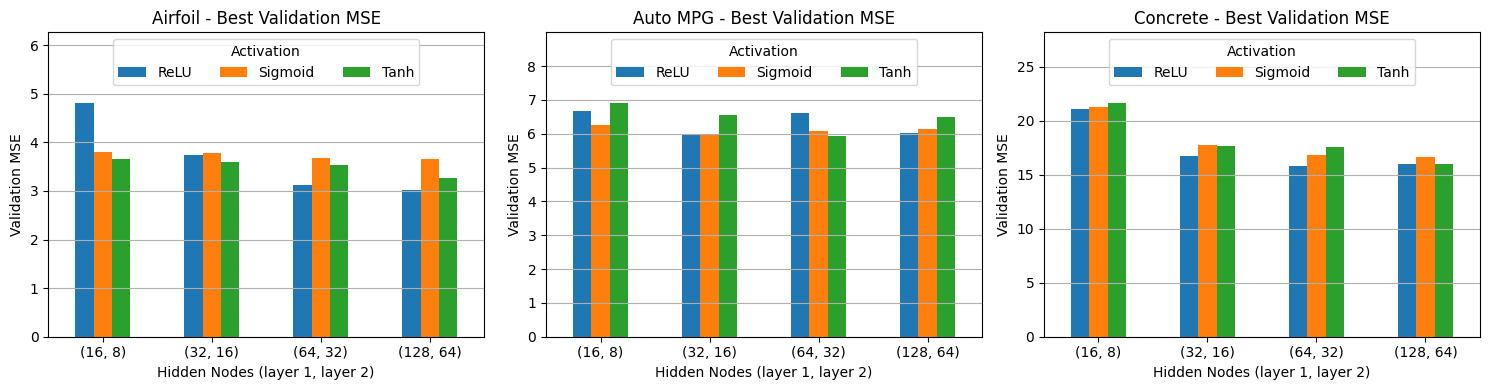

In [12]:
# sensitivity: best tuning validation mse for each activation function and hidden layer size
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, results) in zip(axes, tuning_results.items()):
    pivot = results.groupby(["hidden1", "hidden2", "activation"])["val_mse"].min().unstack("activation")
    pivot.index = [f"({h1}, {h2})" for h1, h2 in pivot.index]
    pivot.plot(kind="bar", ax=ax, rot=0)
    ax.set_ylim(0, pivot.max().max() * 1.3)   # leave room above the bars for the legend
    ax.legend(title="Activation", loc="upper center", ncol=3)
    ax.set_title(f"{name} - Best Validation MSE")
    ax.set_xlabel("Hidden Nodes (layer 1, layer 2)")
    ax.set_ylabel("Validation MSE")
    ax.grid(True, axis="y")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/tuning_sensitivity.png", dpi=150)
plt.show()

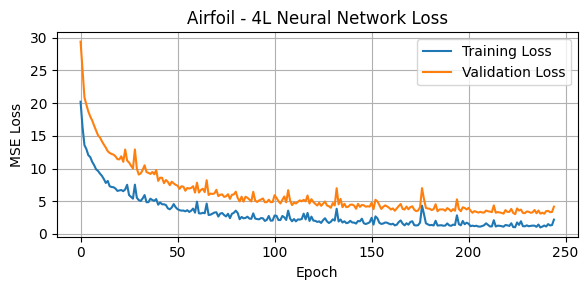

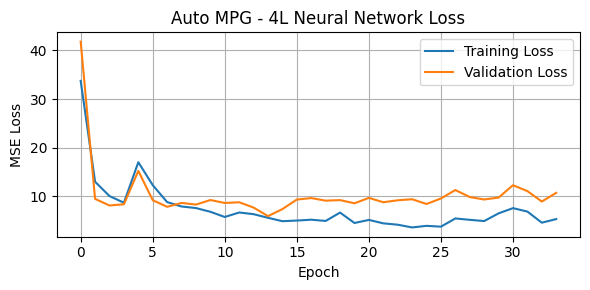

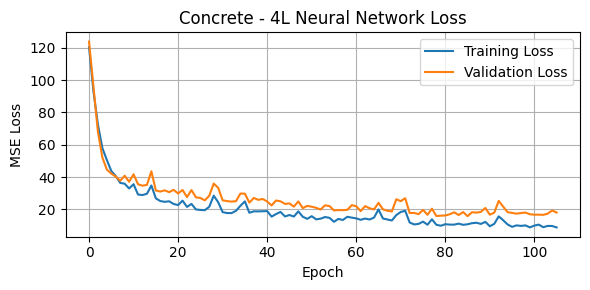

In [13]:
# plot training and validation loss curves for the best configuration
def plot_loss(history, dataset_name):
    plt.figure(figsize=(6, 3))
    plt.plot(history["train"], label="Training Loss")
    plt.plot(history["val"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"{dataset_name} - 4L Neural Network Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_loss.png", dpi=150)
    plt.show()

for name, history in histories.items():
    plot_loss(history, name)

## Model Training

In [14]:
# train final 4L neural network on the full training set using the best hyperparameters
def train_final_model(X_train, y_train, params):
    torch.manual_seed(42)
    model = NeuralNet4L(
        X_train.shape[1], params["hidden1"], params["hidden2"], activations[params["activation"]]
    )

    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=params["learning_rate"])
    loader = DataLoader(
        TensorDataset(X_train, y_train), batch_size=params["batch_size"], shuffle=True
    )

    # train for the number of epochs selected by early stopping during tuning
    model.train()
    for epoch in range(params["best_epoch"]):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()

    return model

models = {}
for name, (t, y_scaler) in data.items():
    models[name] = train_final_model(t["X_train"], t["y_train_s"], best_params[name])
    print(f"{name}:", models[name])

Airfoil: NeuralNet4L(
  (hidden1): Linear(in_features=5, out_features=128, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=128, out_features=64, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Auto MPG: NeuralNet4L(
  (hidden1): Linear(in_features=7, out_features=64, bias=True)
  (act1): Tanh()
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (act2): Tanh()
  (output): Linear(in_features=32, out_features=1, bias=True)
)


Concrete: NeuralNet4L(
  (hidden1): Linear(in_features=8, out_features=64, bias=True)
  (act1): ReLU()
  (hidden2): Linear(in_features=64, out_features=32, bias=True)
  (act2): ReLU()
  (output): Linear(in_features=32, out_features=1, bias=True)
)


## Model Evaluation (QoF)

In [15]:
# predictions on the original target scale
def predict(model, X, y_scaler):
    model.eval()
    with torch.no_grad():
        predictions = model(X).numpy()
    return y_scaler.inverse_transform(predictions)

# calculate r², mse, and rmse for neural network predictions
def evaluate_model(model, X, y, y_scaler):
    predictions = predict(model, X, y_scaler)
    r2 = r2_score(y, predictions)
    mse = mean_squared_error(y, predictions)
    rmse = np.sqrt(mse)
    return r2, mse, rmse

In [16]:
# compare in-sample (training) and validation QoF across all three datasets
qof_results = []

for name, (t, y_scaler) in data.items():
    train_r2, train_mse, train_rmse = evaluate_model(models[name], t["X_train"], t["y_train"], y_scaler)
    val_r2, val_mse, val_rmse = evaluate_model(models[name], t["X_test"], t["y_test"], y_scaler)

    qof_results.append({
        "Dataset": name,
        "Train R²": train_r2,
        "Validation R²": val_r2,
        "Train MSE": train_mse,
        "Validation MSE": val_mse,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse
    })

qof_df = pd.DataFrame(qof_results)
qof_df.to_csv(f"{RESULTS_DIR}/4L_qof.csv", index=False)
print("4L Neural Network - Quality of Fit")
print(qof_df.round(4).to_string(index=False))

4L Neural Network - Quality of Fit
 Dataset  Train R²  Validation R²  Train MSE  Validation MSE  Train RMSE  Validation RMSE
 Airfoil    0.9720         0.9643     1.3152          1.7895      1.1468           1.3377
Auto MPG    0.8581         0.8317     8.9528          8.5903      2.9921           2.9309
Concrete    0.9623         0.8691    10.6965         33.7271      3.2706           5.8075


In [17]:
# compare with the PyTorch 2L results (Table 4 of the report, same train/validation split)
qof_2l = pd.DataFrame({
    "Dataset": ["Airfoil", "Auto MPG", "Concrete"],
    "2L Train R²": [0.4977, 0.8255, 0.6053],
    "2L Validation R²": [0.5528, 0.7829, 0.6236]
})
comparison = qof_2l.merge(
    qof_df[["Dataset", "Train R²", "Validation R²"]].rename(
        columns={"Train R²": "4L Train R²", "Validation R²": "4L Validation R²"}
    ),
    on="Dataset"
)
comparison["Validation R² Gain"] = comparison["4L Validation R²"] - comparison["2L Validation R²"]
print("PyTorch 2L vs. 4L Neural Network")
print(comparison.round(4).to_string(index=False))

PyTorch 2L vs. 4L Neural Network
 Dataset  2L Train R²  2L Validation R²  4L Train R²  4L Validation R²  Validation R² Gain
 Airfoil       0.4977            0.5528       0.9720            0.9643              0.4115
Auto MPG       0.8255            0.7829       0.8581            0.8317              0.0488
Concrete       0.6053            0.6236       0.9623            0.8691              0.2455


## Visualizations

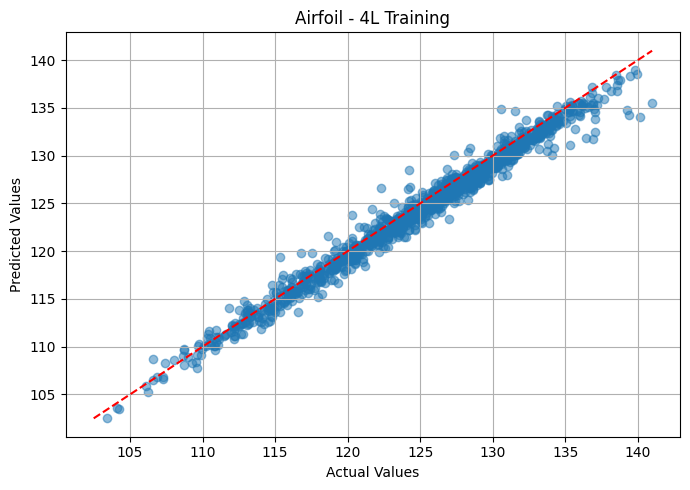

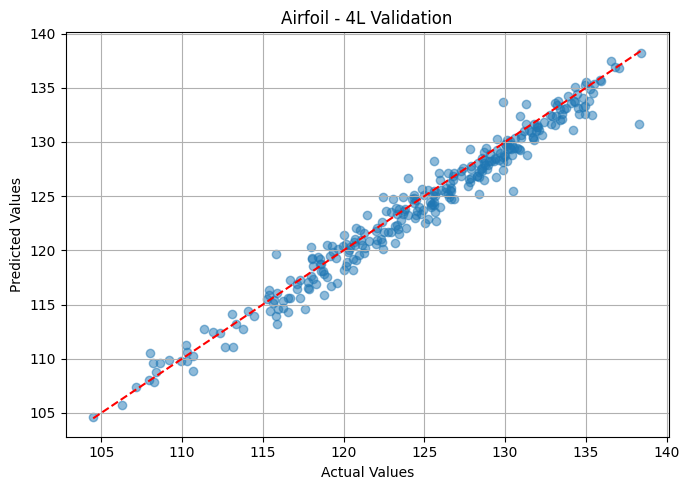

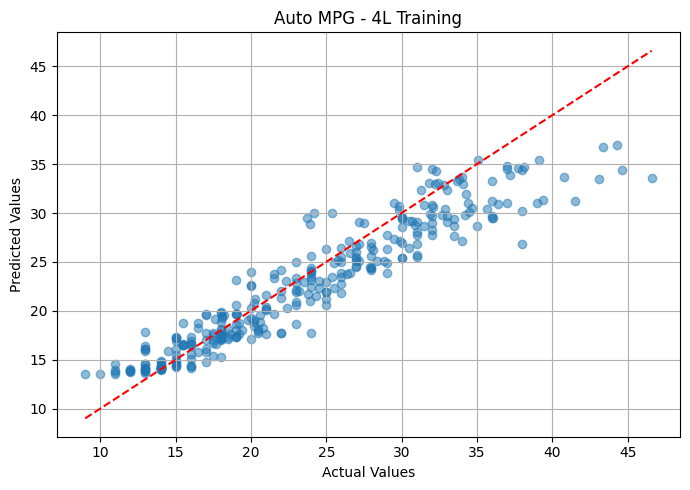

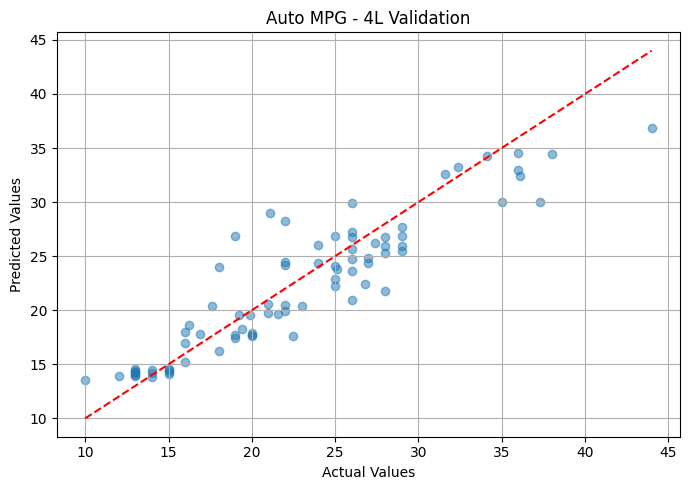

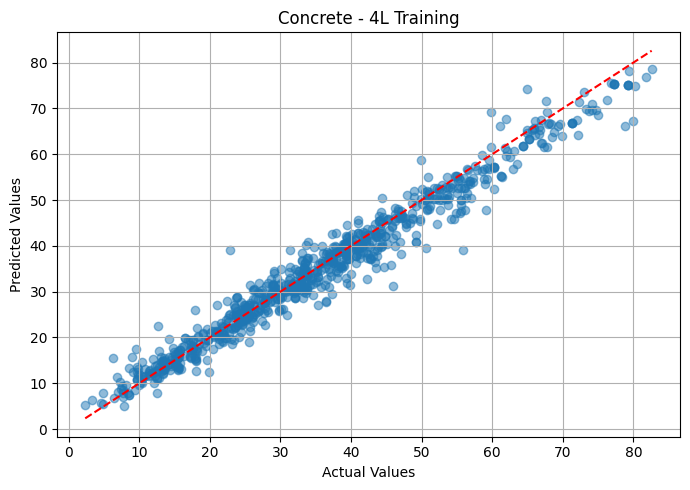

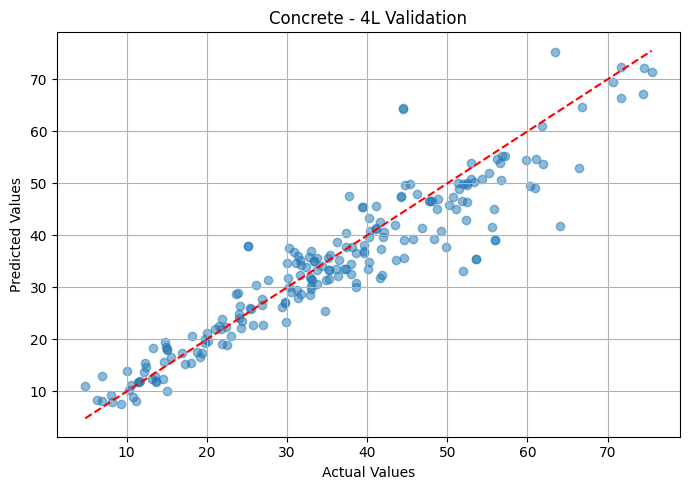

In [18]:
# plot actual vs. predicted values
def plot_predictions(model, X, y, y_scaler, dataset_name, split_name):
    predictions = predict(model, X, y_scaler).flatten()
    actual = y.flatten()

    plt.figure(figsize=(7, 5))
    plt.scatter(actual, predictions, alpha=0.5)

    # perfect prediction line
    min_val = min(actual.min(), predictions.min())
    max_val = max(actual.max(), predictions.max())
    plt.plot([min_val, max_val], [min_val, max_val], "r--")

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{dataset_name} - 4L {split_name}")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_{split_name.lower()}_pred.png", dpi=150)
    plt.show()

for name, (t, y_scaler) in data.items():
    plot_predictions(models[name], t["X_train"], t["y_train"], y_scaler, name, "Training")
    plot_predictions(models[name], t["X_test"], t["y_test"], y_scaler, name, "Validation")

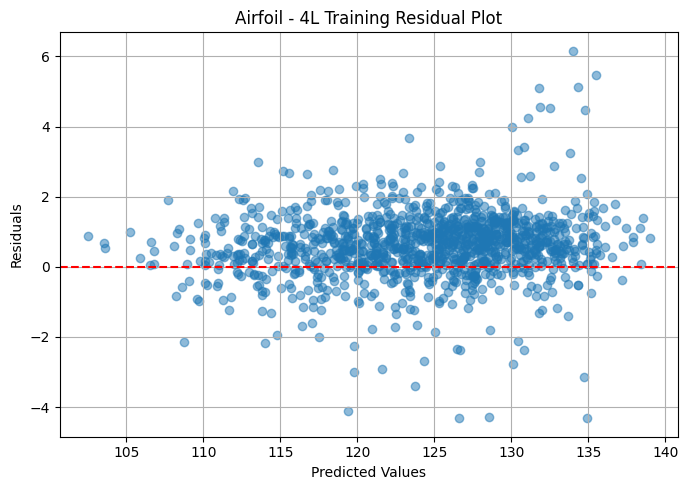

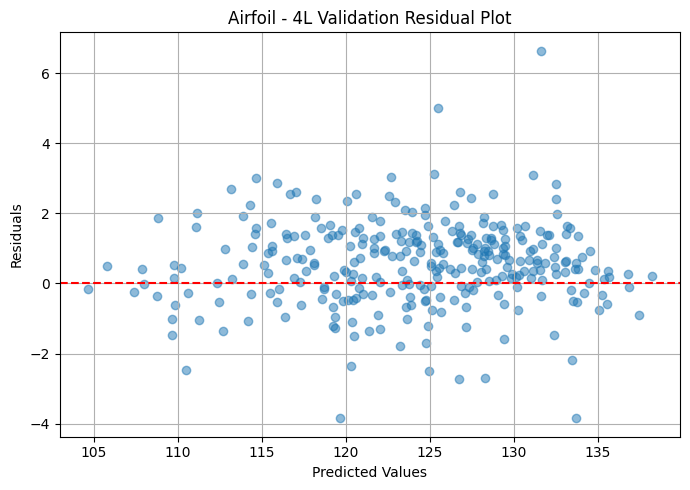

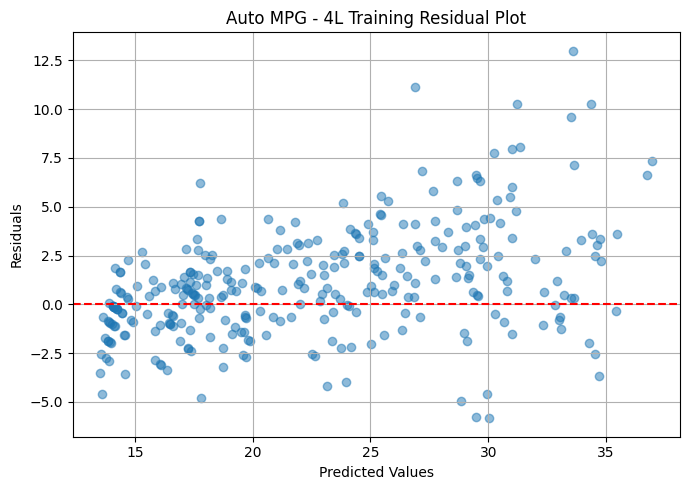

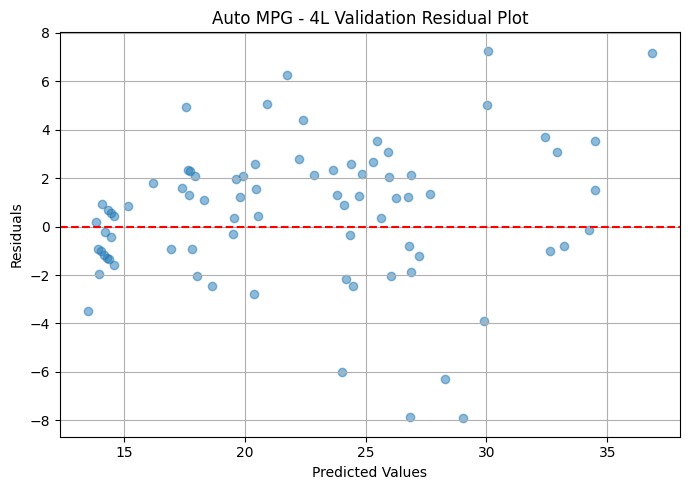

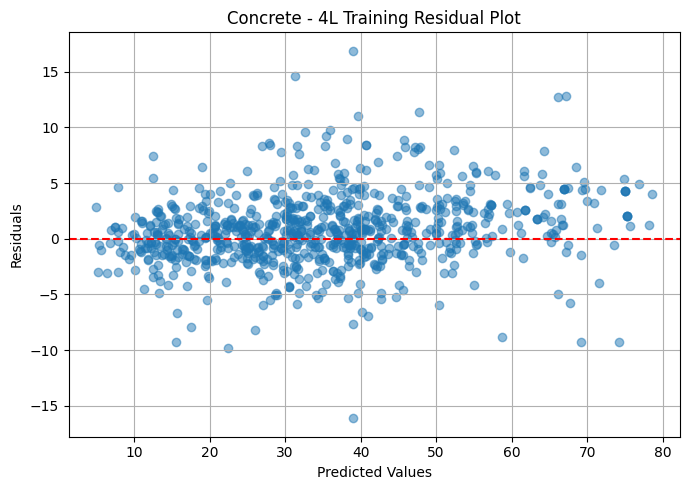

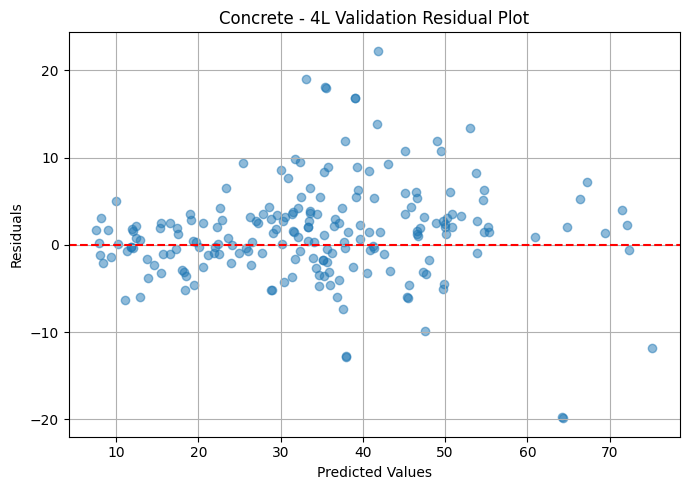

In [19]:
# plot residuals against predicted values
def plot_residuals(model, X, y, y_scaler, dataset_name, split_name):
    predictions = predict(model, X, y_scaler).flatten()
    residuals = y.flatten() - predictions

    plt.figure(figsize=(7, 5))
    plt.scatter(predictions, residuals, alpha=0.5)
    plt.axhline(y=0, color="red", linestyle="--")

    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title(f"{dataset_name} - 4L {split_name} Residual Plot")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{dataset_name.lower().replace(' ', '_')}_{split_name.lower()}_resid.png", dpi=150)
    plt.show()

for name, (t, y_scaler) in data.items():
    plot_residuals(models[name], t["X_train"], t["y_train"], y_scaler, name, "Training")
    plot_residuals(models[name], t["X_test"], t["y_test"], y_scaler, name, "Validation")